## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Giovanni Alejandro Castillo Buitrago" # @param {"type":"string"}
carnet = 1000115755 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una tienda tiene muchos productos registrados en su inventario y, cada vez que necesita consultar uno, recorre toda la lista de principio a fin. Con miles de productos esa búsqueda es lenta (tiempo lineal, O(n)).

Para resolverlo se implementa una **Tabla Hash** construida manualmente, que usa como llave el **código numérico** del producto y la función hash

$$h(\text{código}) = \text{código} \bmod m$$

donde *m* es el tamaño de la tabla, indicado por el usuario. Cada producto guarda: **código, nombre, precio y cantidad disponible**.

Cuando dos productos obtienen el mismo índice (**colisión**, por ejemplo 101 % 7 = 108 % 7 = 3) se resuelve con **encadenamiento**: cada posición de la tabla es la cabeza de una lista enlazada que almacena todos los productos que caen en ese índice. Así, buscar, eliminar o actualizar un producto solo exige recorrer su cadena y no toda la tabla.


## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.


### Requerimientos funcionales
- **RF1.** Crear la Tabla Hash con un tamaño *m* indicado por el usuario; al inicio todas las posiciones están vacías.
- **RF2.** Insertar *n* productos (código, nombre, precio, cantidad) calculando su posición con `h(código) = código % m`.
- **RF3.** Resolver las colisiones mediante encadenamiento.
- **RF4.** No permitir dos productos con el mismo código.
- **RF5.** Buscar un producto por su código, calculando primero la posición con la función hash y revisando solo esa cadena. Si no existe, mostrar *"El producto no está registrado."*
- **RF6.** Eliminar un producto por su código sin afectar a los demás. Si no existe, mostrar *"No se encontró el producto."*
- **RF7.** Actualizar la cantidad disponible de un producto, buscándolo con la Tabla Hash.
- **RF8.** Mostrar el contenido completo de la tabla, evidenciando todas las entradas de las posiciones con colisiones.

### Requerimientos no funcionales
- **RNF1. Eficiencia:** buscar, insertar y eliminar deben ser O(1) en promedio; nunca se recorre toda la tabla para una búsqueda.
- **RNF2. Implementación manual:** la Tabla Hash y las listas enlazadas se programan desde cero, sin `dict`, `set` ni librerías de estructuras de datos.
- **RNF3. Claridad:** código modular, con nombres descriptivos y comentarios.
- **RNF4. Robustez:** valida el tamaño *m* (entero positivo) y las entradas numéricas sin que el programa se caiga.
- **RNF5. Ejecutable:** todo el programa corre desde un único `main()` con menú en Python 3, sin dependencias externas salvo `matplotlib` para la gráfica.
- **RNF6. Usabilidad:** mensajes claros y tabla con formato legible.


## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.

**HU1 – Crear la tabla**
*Como* encargado de la tienda, *quiero* indicar el tamaño *m* de la tabla hash, *para* organizar mi inventario según la capacidad que necesito.
**Criterios de aceptación:**
- La tabla se crea con *m* posiciones, todas en estado "Vacío".
- Si *m* no es un entero positivo, el programa informa el error.

**HU2 – Registrar productos**
*Como* encargado de la tienda, *quiero* registrar productos con su código, nombre, precio y cantidad, *para* tenerlos disponibles para consulta.
**Criterios de aceptación:**
- Cada producto se guarda en la posición `código % m`.
- Si dos productos caen en la misma posición, ambos se conservan encadenados.
- Si el código ya existe, el producto no se registra y se muestra un mensaje de error.

**HU3 – Consultar un producto**
*Como* vendedor, *quiero* buscar un producto por su código, *para* conocer su precio y existencias rápidamente.
**Criterios de aceptación:**
- Se calcula la posición con la función hash y solo se revisa esa cadena.
- Si existe, se muestran código, nombre, precio y cantidad disponible.
- Si no existe, se muestra "El producto no está registrado."

**HU4 – Eliminar un producto**
*Como* encargado de la tienda, *quiero* eliminar un producto descontinuado, *para* mantener el inventario actualizado.
**Criterios de aceptación:**
- Solo se elimina el producto con ese código; los demás de la misma posición se conservan.
- Si el código no existe, se muestra "No se encontró el producto."

**HU5 – Actualizar el inventario**
*Como* encargado de la tienda, *quiero* modificar la cantidad disponible de un producto, *para* reflejar las ventas y las compras.
**Criterios de aceptación:**
- El producto se localiza mediante la Tabla Hash.
- Tras actualizar se muestra "Inventario actualizado correctamente." con la nueva cantidad.
- Si el producto no existe, se informa que no se encontró.

**HU6 – Visualizar la tabla**
*Como* encargado de la tienda, *quiero* ver el contenido completo de la tabla, *para* revisar cómo están distribuidos los productos y detectar colisiones.
**Criterios de aceptación:**
- Se listan todas las posiciones, de 0 a *m*-1.
- Las posiciones vacías muestran "Vacío" y las posiciones con colisión muestran todos sus productos.


## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general



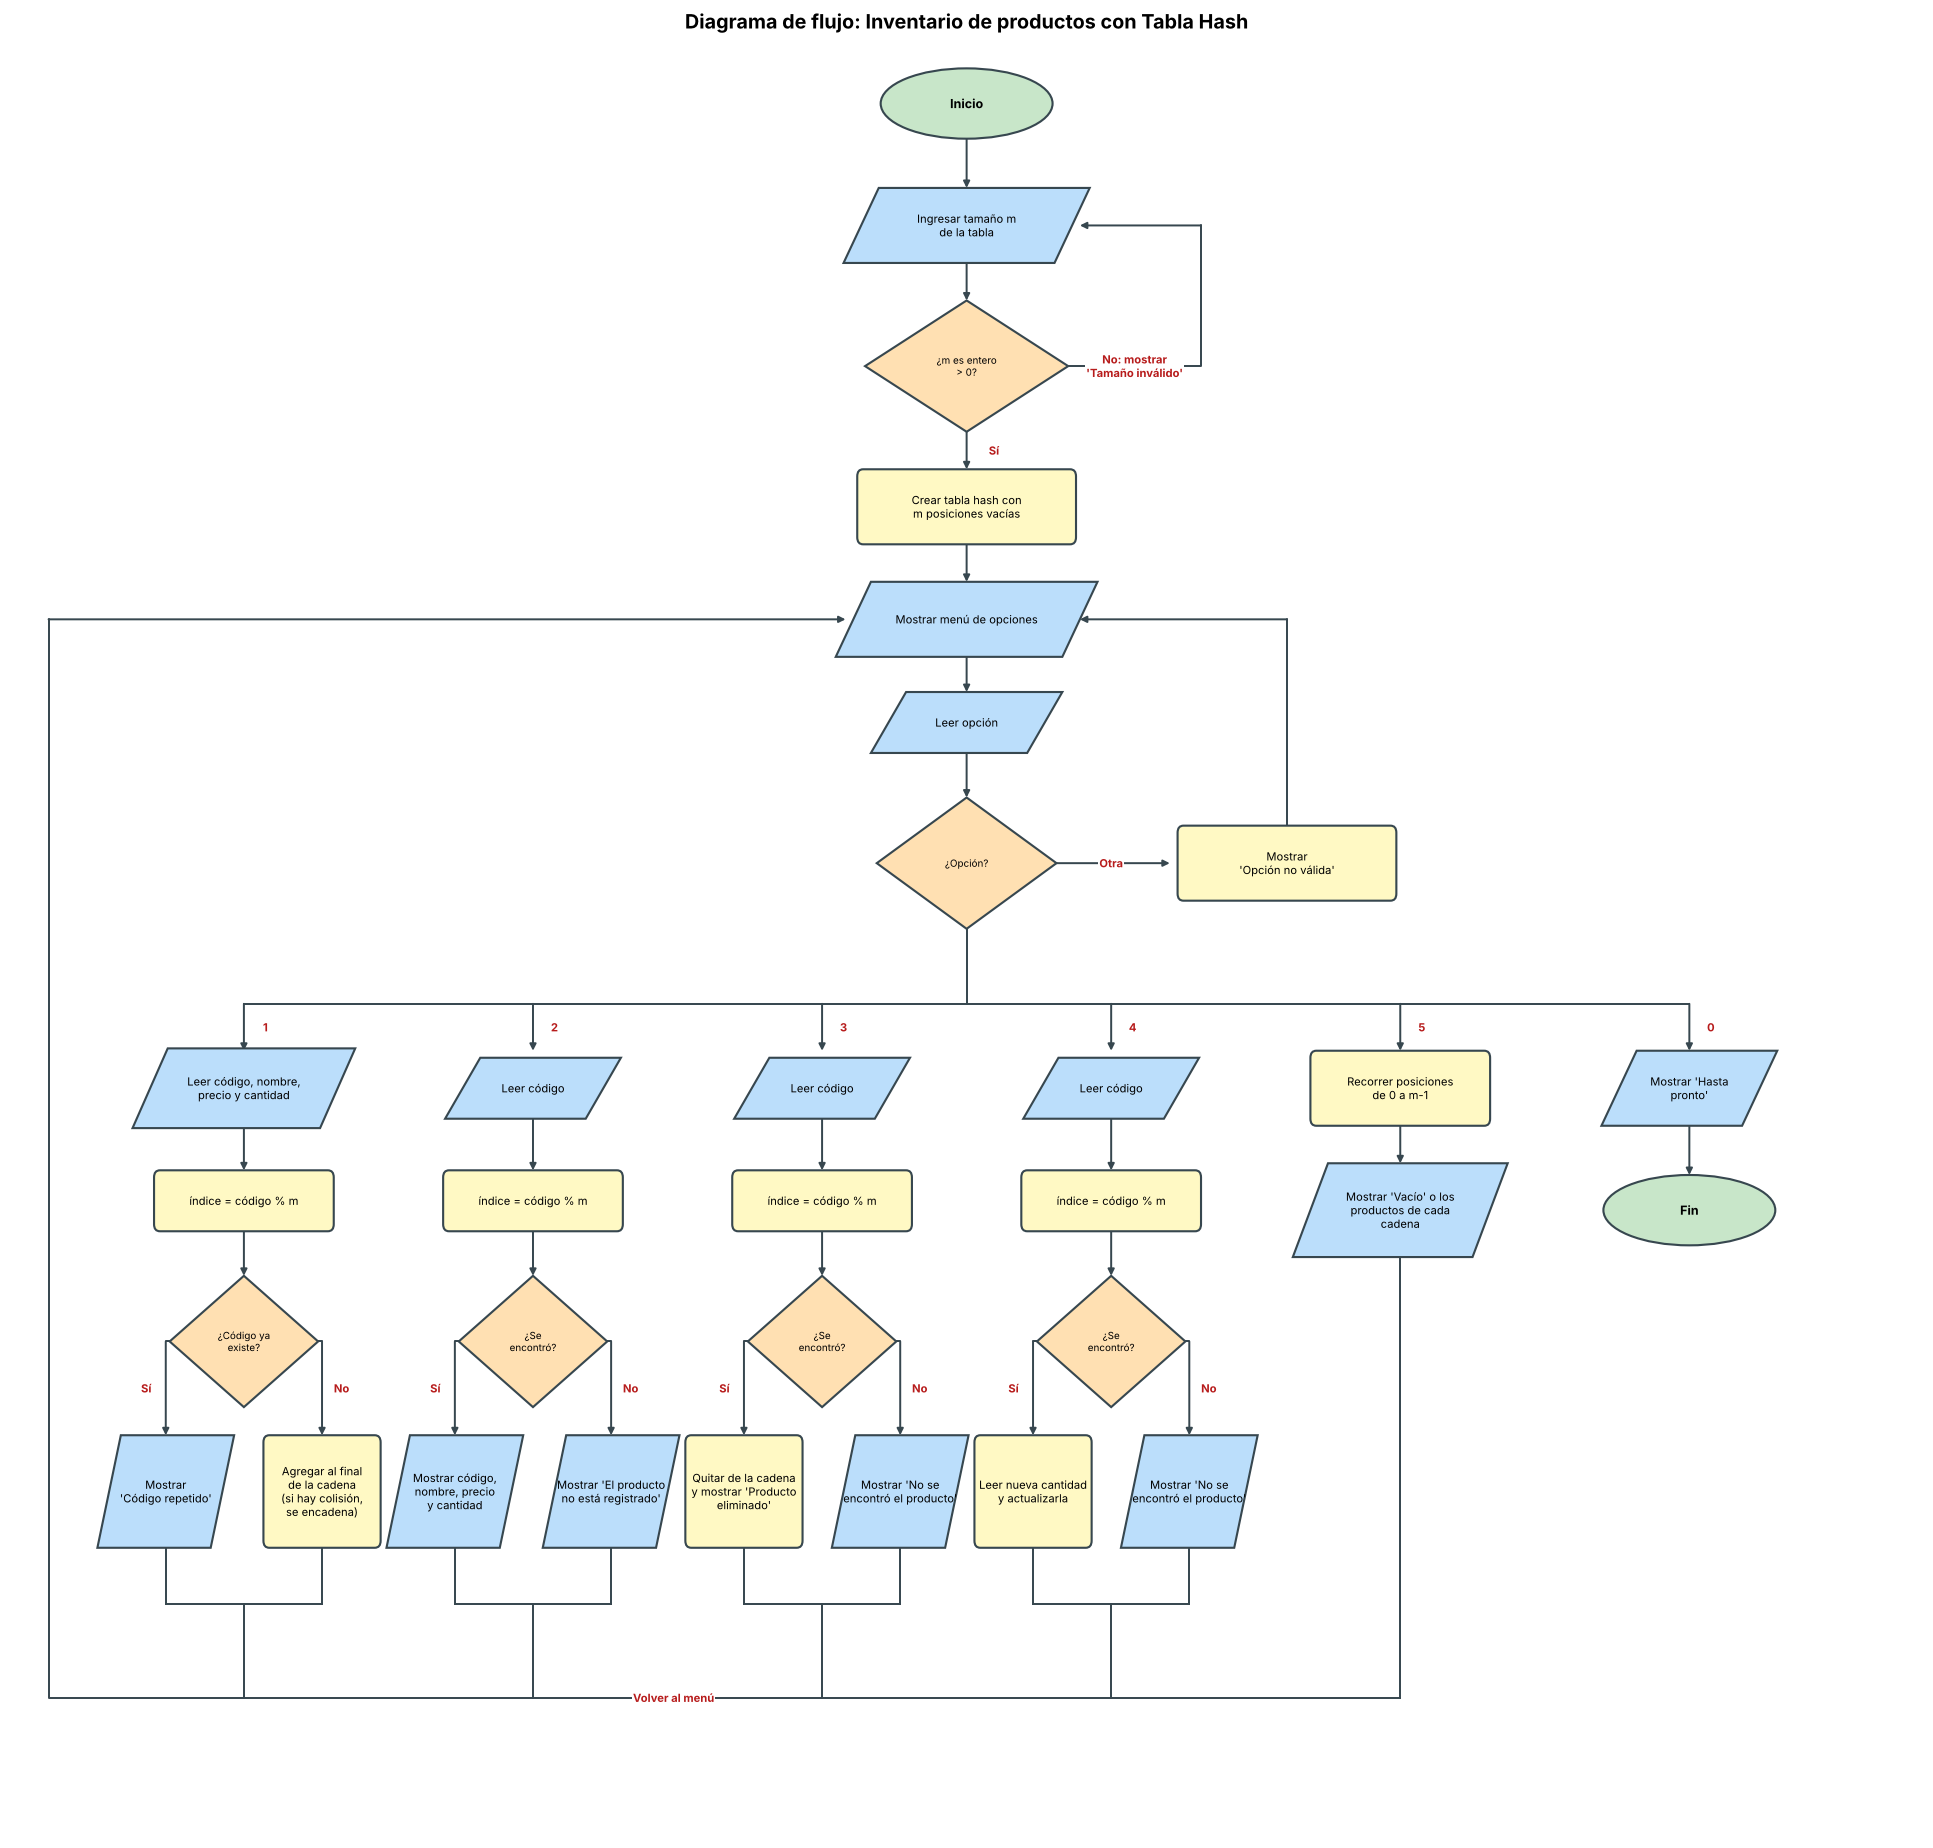

Adjunta imagen y descríbelo claramente.


### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica

### Justificación
Sea **n** el número de productos almacenados y **m** el tamaño de la tabla. Todas las operaciones siguen el mismo patrón:

1. Calcular el índice con `código % m` → 1 paso (operación aritmética).
2. Acceder a la posición del arreglo `tabla[índice]` → 1 paso (acceso directo, sin recorrer).
3. Recorrer **solo la cadena** de esa posición comparando códigos → *k* pasos, donde *k* es el largo de la cadena.

El costo depende entonces de cuántos productos haya en la cadena, y eso depende de la distribución de los códigos. Definiendo el **factor de carga** α = n / m, en el caso promedio (códigos bien repartidos) la longitud esperada de una cadena es α, y como α se mantiene constante cuando *m* es proporcional a *n*, las operaciones son O(1).

### Función T[n] (cantidad de pasos de la búsqueda)

| Caso | Situación | T(n) | Orden |
|---|---|---|---|
| **Mejor** | El producto es la cabeza de su cadena (o la cadena tiene un solo elemento) | T(n) = 1 + 1 + 1 = **3** | Θ(1) |
| **Promedio** | Los códigos se reparten uniformemente | T(n) = 2 + (1 + α) ≈ **3 + n/m** | O(1) si m ∝ n |
| **Peor** | Los *n* productos caen en la misma posición y se busca el último (o uno inexistente) | T(n) = 1 + 1 + n = **n + 2** | O(n) |

Las demás operaciones tienen el mismo costo, porque todas empiezan buscando en la cadena:

| Operación | Mejor caso | Peor caso |
|---|---|---|
| Insertar (revisa duplicados y agrega al final de la cadena) | O(1) | O(n) |
| Buscar | O(1) | O(n) |
| Eliminar | O(1) | O(n) |
| Actualizar cantidad (usa buscar) | O(1) | O(n) |
| Mostrar la tabla | Θ(m + n) | Θ(m + n) |

**Conclusión:** en la práctica la Tabla Hash es O(1) en promedio, frente a O(n) de recorrer una lista completa. El peor caso O(n) solo ocurre cuando todas las llaves colisionan (por ejemplo, códigos que son todos múltiplos de *m*).

### Gráfica de mejor y peor caso
La gráfica se genera desde el menú (opción 9) de la celda de código de la sección 6. Se midió con un contador de comparaciones: el **peor caso** (todos los códigos múltiplos de *m* = 7, buscando el último) crece linealmente siguiendo T(n) = n + 2, mientras que el **mejor caso** se mantiene constante en 3 pasos sin importar cuántos productos haya.


## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.

Implementación completa en **una sola celda** con un único `main()`. Al ejecutarla pide el tamaño *m* de la tabla y abre un **menú** para elegir qué hacer: registrar productos, buscar, eliminar, actualizar la cantidad, mostrar la tabla, crear una nueva tabla, correr una demostración automática, ejecutar los tests o ver la gráfica de complejidad.

La salida que se ve debajo es una sesión real del programa con las opciones del menú ejecutadas en orden (creación, inserción con colisión, búsqueda exitosa e inexistente, eliminación, actualización, estado final, tests y gráfica).


INVENTARIO DE PRODUCTOS CON TABLA HASH
Ingrese el tamaño de la tabla hash: 7
              TABLA HASH
0 -> Vacío
1 -> Vacío
2 -> Vacío
3 -> Vacío
4 -> Vacío
5 -> Vacío
6 -> Vacío

MENÚ
1) Registrar productos
2) Buscar un producto
3) Eliminar un producto
4) Actualizar cantidad disponible
5) Mostrar la tabla hash
6) Crear una nueva tabla (cambiar m)
7) Demostración automática
8) Ejecutar tests
9) Gráfica de mejor y peor caso
0) Salir
Opción: 1
¿Cuántos productos desea registrar?: 7
Código: 101
Nombre: Arroz
Precio: 4500
Cantidad: 20
101 % 7 = 3 -> Arroz guardado en la posición 3
Código: 205
Nombre: Leche
Precio: 3800
Cantidad: 15
205 % 7 = 2 -> Leche guardado en la posición 2
Código: 312
Nombre: Café
Precio: 12000
Cantidad: 10
312 % 7 = 4 -> Café guardado en la posición 4
Código: 423
Nombre: Pan
Precio: 2500
Cantidad: 30
423 % 7 = 3 -> Pan guardado en la posición 3
Código: 108
Nombre: Huevos
Precio: 16000
Cantidad: 12
108 % 7 = 3 -> Huevos guardado en la posición 3
Código: 115
Nombre: Az

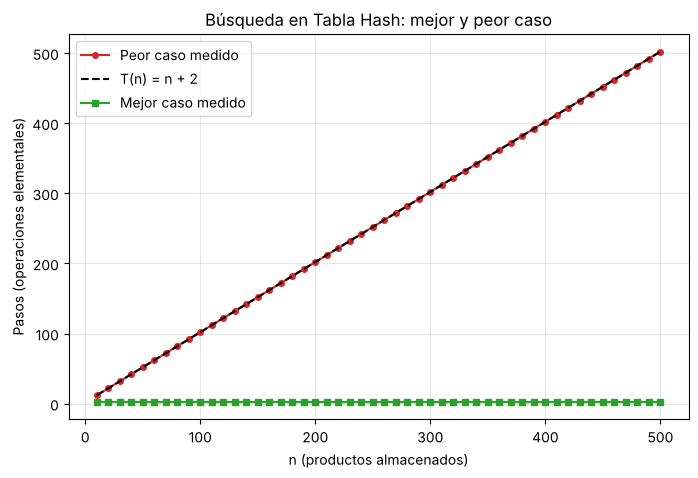


MENÚ
1) Registrar productos
2) Buscar un producto
3) Eliminar un producto
4) Actualizar cantidad disponible
5) Mostrar la tabla hash
6) Crear una nueva tabla (cambiar m)
7) Demostración automática
8) Ejecutar tests
9) Gráfica de mejor y peor caso
0) Salir
Opción: 0
Hasta pronto.


In [ ]:

import matplotlib.pyplot as plt


class Producto:
    """Nodo de la lista enlazada: guarda un producto y apunta al siguiente."""

    def __init__(self, codigo, nombre, precio, cantidad):
        self.codigo = codigo
        self.nombre = nombre
        self.precio = precio
        self.cantidad = cantidad
        self.siguiente = None


def formato_precio(valor):
    """4500 -> $4.500"""
    return "$" + f"{valor:,}".replace(",", ".")


class TablaHash:
    """Tabla Hash manual con encadenamiento (listas enlazadas)."""

    def __init__(self, m):
        if not isinstance(m, int) or m <= 0:
            raise ValueError("El tamaño m debe ser un entero positivo.")
        self.m = m
        self.tabla = [None] * m    
        self.n = 0                  
        self.comparaciones = 0      

    # h(código) = código % m
    def hash(self, codigo):
        return codigo % self.m

   
    def insertar(self, codigo, nombre, precio, cantidad):
        indice = self.hash(codigo)
        actual = self.tabla[indice]
        ultimo = None
        while actual is not None:            
            self.comparaciones += 1
            if actual.codigo == codigo:     
                return False
            ultimo = actual
            actual = actual.siguiente
        nuevo = Producto(codigo, nombre, precio, cantidad)
        if ultimo is None:
            self.tabla[indice] = nuevo
        else:
            ultimo.siguiente = nuevo
        self.n += 1
        return True

    def buscar(self, codigo):
        actual = self.tabla[self.hash(codigo)]   
        while actual is not None:
            self.comparaciones += 1
            if actual.codigo == codigo:
                return actual
            actual = actual.siguiente
        return None

    
    def eliminar(self, codigo):
        indice = self.hash(codigo)
        actual = self.tabla[indice]
        anterior = None
        while actual is not None:
            self.comparaciones += 1
            if actual.codigo == codigo:
                if anterior is None:
                    self.tabla[indice] = actual.siguiente
                else:
                    anterior.siguiente = actual.siguiente
                self.n -= 1
                return True
            anterior = actual
            actual = actual.siguiente
        return False

    
    def actualizar_cantidad(self, codigo, nueva_cantidad):
        producto = self.buscar(codigo)
        if producto is None:
            return False
        producto.cantidad = nueva_cantidad
        return True

    
    def mostrar(self):
        print("=" * 40)
        print(" " * 14 + "TABLA HASH")
        print("=" * 40)
        for i in range(self.m):
            prefijo = f"{i} -> "
            actual = self.tabla[i]
            if actual is None:
                print(prefijo + "Vacío")
                continue
            sangria = " " * len(prefijo)
            primero = True
            while actual is not None:
                linea = f"{actual.codigo} - {actual.nombre}"
                print((prefijo if primero else sangria) + linea)
                primero = False
                actual = actual.siguiente
        print("=" * 40)



def registrar(tabla, codigo, nombre, precio, cantidad):
    indice = tabla.hash(codigo)
    if tabla.insertar(codigo, nombre, precio, cantidad):
        print(f"{codigo} % {tabla.m} = {indice} -> {nombre} guardado en la posición {indice}")
    else:
        print(f"Error: ya existe un producto con el código {codigo}.")


def consultar(tabla, codigo):
    print(f"Ingrese el código del producto: {codigo}")
    print(f"Posición calculada: {codigo} % {tabla.m} = {tabla.hash(codigo)}")
    p = tabla.buscar(codigo)
    if p is None:
        print("El producto no está registrado.")
    else:
        print("Producto encontrado")
        print(f"Código: {p.codigo}")
        print(f"Nombre: {p.nombre}")
        print(f"Precio: {formato_precio(p.precio)}")
        print(f"Cantidad disponible: {p.cantidad}")


def borrar(tabla, codigo):
    print(f"Código del producto que desea eliminar: {codigo}")
    if tabla.eliminar(codigo):
        print("Producto eliminado correctamente.")
    else:
        print("No se encontró el producto.")


def modificar_inventario(tabla, codigo, nueva):
    p = tabla.buscar(codigo)
    if p is None:
        print("No se encontró el producto.")
        return
    print(f"Código: {p.codigo}")
    print(f"Producto: {p.nombre}")
    print(f"Cantidad actual: {p.cantidad}")
    print(f"Nueva cantidad: {nueva}")
    tabla.actualizar_cantidad(codigo, nueva)
    print("Inventario actualizado correctamente.")
    print(f"{p.nombre} - {p.cantidad} unidades")



def ejecutar_tests():
    t = TablaHash(7)
    assert t.n == 0 and all(c is None for c in t.tabla), "T1: la tabla nueva debe estar vacía"
    print("✔ T1  Creación: tabla de tamaño 7 vacía")

    assert t.hash(101) == 3 and t.hash(108) == 3 and t.hash(205) == 2
    print("✔ T2  Función hash: 101 % 7 = 3, 108 % 7 = 3, 205 % 7 = 2")

    assert t.insertar(101, "Arroz", 4500, 20)
    assert t.insertar(205, "Leche", 3800, 15)
    assert t.n == 2 and t.tabla[3].codigo == 101 and t.tabla[2].codigo == 205
    print("✔ T3  Inserción en la posición calculada por el hash")

    assert t.insertar(108, "Huevos", 16000, 12)
    assert t.insertar(115, "Azúcar", 9000, 8)
    assert t.tabla[3].codigo == 101 and t.tabla[3].siguiente.codigo == 108 \
        and t.tabla[3].siguiente.siguiente.codigo == 115
    print("✔ T4  Colisión: 101, 108 y 115 quedan encadenados en la posición 3")

    assert t.insertar(101, "Otro", 1, 1) is False and t.n == 4
    print("✔ T5  No permite códigos repetidos")

    p = t.buscar(108)
    assert p is not None and p.nombre == "Huevos" and p.precio == 16000 and p.cantidad == 12
    print("✔ T6  Búsqueda exitosa (108 -> Huevos)")

    assert t.buscar(999) is None and t.buscar(10) is None
    print("✔ T7  Búsqueda de producto inexistente devuelve None")

    assert t.eliminar(108) is True and t.buscar(108) is None
    assert t.tabla[3].codigo == 101 and t.tabla[3].siguiente.codigo == 115 and t.n == 3
    print("✔ T8  Eliminar un nodo del medio de la cadena (108)")

    assert t.eliminar(101) is True and t.tabla[3].codigo == 115
    print("✔ T9  Eliminar la cabeza de la cadena (101)")

    assert t.eliminar(115) is True and t.tabla[3] is None
    print("✔ T10 Eliminar el último elemento deja la posición vacía")

    assert t.eliminar(999) is False
    print("✔ T11 Eliminar un código inexistente devuelve False")

    assert t.actualizar_cantidad(205, 35) is True and t.buscar(205).cantidad == 35
    print("✔ T12 Actualizar cantidad (205: 15 -> 35)")

    assert t.actualizar_cantidad(999, 5) is False
    print("✔ T13 Actualizar un producto inexistente devuelve False")

    try:
        TablaHash(0)
        assert False, "debía lanzar ValueError"
    except ValueError:
        pass
    print("✔ T14 Tamaño m inválido lanza ValueError")

    t2 = TablaHash(1000)
    for c in range(1000):
        t2.insertar(c, "P", 1, 1)
    t2.comparaciones = 0
    t2.buscar(777)
    assert t2.comparaciones == 1
    print("✔ T15 Búsqueda con 1000 productos: 1 sola comparación (no recorre la tabla)")
    print("\nTodos los tests pasaron correctamente.")



def graficar_complejidad():
    tamanos = list(range(10, 501, 10))
    pasos_mejor, pasos_peor = [], []
    for n in tamanos:
        m = 7
        t = TablaHash(m)
        for k in range(1, n + 1):
            t.insertar(k * m, "P", 1, 1)
        t.comparaciones = 0
        t.buscar(n * m)                       
        pasos_peor.append(t.comparaciones + 2)   

       
        t.comparaciones = 0
        t.buscar(1 * m)
        pasos_mejor.append(t.comparaciones + 2)

    plt.figure(figsize=(8, 5))
    plt.plot(tamanos, pasos_peor, "o-", color="tab:red", markersize=4, label="Peor caso medido")
    plt.plot(tamanos, [n + 2 for n in tamanos], "--", color="black", label="T(n) = n + 2")
    plt.plot(tamanos, pasos_mejor, "s-", color="tab:green", markersize=4, label="Mejor caso medido")
    plt.title("Búsqueda en Tabla Hash: mejor y peor caso")
    plt.xlabel("n (productos almacenados)")
    plt.ylabel("Pasos (operaciones elementales)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()



def demostracion():
    print("#" * 60)
    print("# 1. CREACIÓN DE LA TABLA HASH")
    print("#" * 60)
    m = 7
    print(f"Ingrese el tamaño de la tabla hash: {m}")
    tabla = TablaHash(m)
    tabla.mostrar()

    print("\n" + "#" * 60)
    print("# 2. INSERCIÓN DE PRODUCTOS (incluye colisiones)")
    print("#" * 60)
    productos = [
        (101, "Arroz", 4500, 20),
        (205, "Leche", 3800, 15),
        (312, "Café", 12000, 10),
        (423, "Pan", 2500, 30),
        (108, "Huevos", 16000, 12),   
        (115, "Azúcar", 9000, 8),     
        (302, "Galletas", 3000, 25),
    ]
    print(f"¿Cuántos productos desea registrar?: {len(productos)}")
    for codigo, nombre, precio, cantidad in productos:
        registrar(tabla, codigo, nombre, precio, cantidad)
    print("\nIntento de insertar un código repetido:")
    registrar(tabla, 101, "Arroz Premium", 5000, 5)
    print("\nEstado de la tabla después de insertar:")
    tabla.mostrar()

    print("\n" + "#" * 60)
    print("# 3. COLISIÓN RESUELTA POR ENCADENAMIENTO")
    print("#" * 60)
    print("Los códigos 101, 423, 108 y 115 dan 3 al aplicar % 7 y quedan")
    print("encadenados en la misma posición (ver índice 3 de la tabla).")

    print("\n" + "#" * 60)
    print("# 4. BÚSQUEDA DE PRODUCTOS")
    print("#" * 60)
    print("--- Búsqueda exitosa ---")
    consultar(tabla, 108)
    print("\n--- Búsqueda de un producto inexistente ---")
    consultar(tabla, 999)

    print("\n" + "#" * 60)
    print("# 5. ELIMINACIÓN DE UN PRODUCTO")
    print("#" * 60)
    print("Antes:")
    tabla.mostrar()
    borrar(tabla, 108)
    print("\nDespués:")
    tabla.mostrar()
    print("\nEliminar un código que no existe:")
    borrar(tabla, 999)

    print("\n" + "#" * 60)
    print("# 6. ACTUALIZACIÓN DEL INVENTARIO")
    print("#" * 60)
    modificar_inventario(tabla, 101, 35)
    print("\nActualizar un producto inexistente:")
    modificar_inventario(tabla, 999, 10)

    print("\n" + "#" * 60)
    print("# 7. ESTADO FINAL DE LA TABLA HASH")
    print("#" * 60)
    tabla.mostrar()



def leer_entero(mensaje, minimo=None):
    while True:
        try:
            valor = int(input(mensaje))
            if minimo is not None and valor < minimo:
                print(f"Debe ser un entero mayor o igual a {minimo}.")
                continue
            return valor
        except ValueError:
            print("Entrada inválida. Ingrese un número entero.")


def leer_texto(mensaje):
    while True:
        texto = input(mensaje).strip()
        if texto:
            return texto
        print("El nombre no puede estar vacío.")



def main():
    print("INVENTARIO DE PRODUCTOS CON TABLA HASH")
    m = leer_entero("Ingrese el tamaño de la tabla hash: ", minimo=1)
    tabla = TablaHash(m)
    tabla.mostrar()

    while True:
        print("\n" + "=" * 40)
        print("MENÚ")
        print("=" * 40)
        print("1) Registrar productos")
        print("2) Buscar un producto")
        print("3) Eliminar un producto")
        print("4) Actualizar cantidad disponible")
        print("5) Mostrar la tabla hash")
        print("6) Crear una nueva tabla (cambiar m)")
        print("7) Demostración automática")
        print("8) Ejecutar tests")
        print("9) Gráfica de mejor y peor caso")
        print("0) Salir")
        opcion = leer_entero("Opción: ")

        if opcion == 1:
            n = leer_entero("¿Cuántos productos desea registrar?: ", minimo=1)
            for _ in range(n):
                codigo = leer_entero("Código: ")
                nombre = leer_texto("Nombre: ")
                precio = leer_entero("Precio: ", minimo=0)
                cantidad = leer_entero("Cantidad: ", minimo=0)
                registrar(tabla, codigo, nombre, precio, cantidad)
            tabla.mostrar()
        elif opcion == 2:
            consultar(tabla, leer_entero("Ingrese el código del producto: "))
        elif opcion == 3:
            borrar(tabla, leer_entero("Código del producto que desea eliminar: "))
        elif opcion == 4:
            codigo = leer_entero("Código: ")
            if tabla.buscar(codigo) is None:
                print("No se encontró el producto.")
            else:
                modificar_inventario(tabla, codigo, leer_entero("Nueva cantidad: ", minimo=0))
        elif opcion == 5:
            tabla.mostrar()
        elif opcion == 6:
            m = leer_entero("Ingrese el tamaño de la tabla hash: ", minimo=1)
            tabla = TablaHash(m)
            tabla.mostrar()
        elif opcion == 7:
            demostracion()
        elif opcion == 8:
            ejecutar_tests()
        elif opcion == 9:
            graficar_complejidad()
        elif opcion == 0:
            print("Hasta pronto.")
            break
        else:
            print("Opción no válida.")


if __name__ == "__main__":
    main()



## 7) Tests aplicados **[15 pts]**

Los tests están en la misma celda (función `ejecutar_tests()`, opción 8 del menú) y usan `assert`; se ven en la salida de la celda de la sección 6. Cobertura:

| # | Prueba | Resultado esperado |
|---|---|---|
| T1 | Crear tabla de tamaño 7 | Todas las posiciones vacías, n = 0 |
| T2 | Función hash | 101 % 7 = 3, 108 % 7 = 3, 205 % 7 = 2 |
| T3 | Insertar 101 y 205 | Quedan en las posiciones 3 y 2 |
| T4 | **Colisión**: insertar 108 y 115 | 101 → 108 → 115 encadenados en la posición 3 |
| T5 | Insertar código repetido | Se rechaza, n no cambia |
| T6 | **Búsqueda exitosa** de 108 | Huevos, $16.000, 12 unidades |
| T7 | **Búsqueda inexistente** (999, 10) | Devuelve `None` |
| T8 | **Eliminar** 108 (nodo del medio) | La cadena queda 101 → 115 |
| T9 | Eliminar la cabeza (101) | La cabeza pasa a ser 115 |
| T10 | Eliminar el último de la cadena | La posición queda vacía |
| T11 | Eliminar código inexistente | Devuelve `False` |
| T12 | **Actualizar** cantidad de 205 | 15 → 35 |
| T13 | Actualizar producto inexistente | Devuelve `False` |
| T14 | Tamaño m = 0 | Lanza `ValueError` |
| T15 | Buscar con 1000 productos y m = 1000 | 1 sola comparación, sin recorrer la tabla |

Además, la sesión del menú muestra el **estado final de la tabla hash** (opción 5).
